In [35]:
from google.colab import drive
drive.mount('/content/drive')
# Navigate to the Sheridan folder
%cd /content/drive/MyDrive/Sheridan

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Sheridan


In [36]:
from engine import *
ms, loans, accounts, districts = load_data("Data")
profiles = build_profiles(ms, loans)
p = get_profile(profiles, 20111)
apply_shock(p, PRESETS["EI job loss (55%, 6 mo)"])

{'shock': {'income_mult': 0.55,
  'bills_pct': 0.0,
  'spend_add': 0.0,
  'one_off': 0.0,
  'one_off_spend_mult': 0.0,
  'loan_relief': False,
  'months': 6,
  'name': 'EI job loss (55%, 6 mo)'},
 'I': 6339.389999999999,
 'S': 8599.605,
 'H': 0.0,
 'B': 17611.863333333335,
 'P': 2330.19,
 'income_after': 3486.6645,
 'spending_after': 8599.605,
 'one_off_total': 0.0,
 'buffer_left': 17611.863333333335,
 'gap': 5112.9405,
 'runway_base': 7.8,
 'runway_shock': 3.4,
 'runway_label': '3.4 months',
 'months': 6,
 'survives_shock_period': False,
 'runout_month': 4,
 'shortfall_over_period': 13065.779666666662}

In [37]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import engine
import os, sys, importlib
importlib.reload(engine)          # re-run this cell after editing engine.py
from engine import *

pd.set_option("display.max_columns", 50, "display.width", 160)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": .3})

In [38]:
# Load the data and sanity checks
ms, loans, accounts, districts = load_data("Data")
print("monthly_summary:", ms.shape, "| accounts:", ms.account_id.nunique(),
      "| loans:", len(loans), "| months:", ms.month.min(), "->", ms.month.max())

profiles = build_profiles(ms, loans, loan_rule="status")   # official-definition profiles for ALL accounts
profiles.head()

monthly_summary: (185326, 19) | accounts: 4500 | loans: 682 | months: 2020-01 -> 2025-12


,I,F,S,H,n_months,B,flex_card_withdrawals,flex_cash_withdrawals_genuine,flex_transfers_out_other,flex_bank_fees,flex_total,income_cv,spend_cv,pct_months_below_zero,avg_days_below_zero,min_balance_ever,P,running_by_date,running_by_status,loan_rule_mismatch,defaulted,status,has_loan,runway_base,surplus
account_id,,,,,,,,,,,,,,,,,,,,,,,,,
20111,6339.390,2330.06,8599.605,0.00,38,17611.863333,0.0,7425.385,0.00,9.19,7434.575,1.136488,0.937799,0.105263,1.447368,-3755.42,2330.19,True,True,False,1.0,D,True,7.8,-2260.215
20133,24194.040,0.00,20476.190,0.00,25,30197.925000,0.0,20467.000,0.00,9.19,20476.190,0.870143,0.814455,0.000000,0.000000,692.20,0.00,NaN,NaN,NaN,NaN,NaN,False,120.0,3717.850
20134,7958.000,6478.15,8060.520,5166.31,23,16599.456667,0.0,2013.660,0.00,9.19,2022.850,0.271283,0.525504,0.000000,0.000000,188.78,1312.03,True,True,False,0.0,C,True,120.0,-102.520
20143,30870.660,4109.76,34579.700,4109.76,66,39545.621667,0.0,25958.960,3722.13,9.19,29690.280,0.210961,0.405188,0.000000,0.000000,692.20,0.00,False,False,False,0.0,A,True,10.7,-3709.040
20160,13392.435,2814.10,13564.930,2814.10,34,31662.453333,0.0,10741.640,0.00,9.19,10750.830,0.172225,0.518134,0.000000,0.000000,503.42,0.00,NaN,NaN,NaN,NaN,NaN,False,120.0,-172.495


In [39]:
# Edge cases to know about BEFORE a judge finds them live
checks = {
    "accounts with < 6 monthly rows":       int((profiles.n_months < 6).sum()),
    "accounts with I == 0":                 int((profiles.I == 0).sum()),
    "accounts with B <= 0 (runway 0)":      int((profiles.B <= 0).sum()),
    "accounts with a loan":                 int(profiles.has_loan.sum()),
    "accounts with NaN in I,S,H,B":         int(profiles[["I","S","H","B"]].isna().any(axis=1).sum()),
}
for k, v in checks.items(): print(f"{k:38s} {v}")

print("\nBase runway (no shock):")
print(profiles.runway_base.describe().round(1))
print(f"Share with no shortfall (120+): {(profiles.runway_base >= 120).mean():.1%}")

accounts with < 6 monthly rows         0
accounts with I == 0                   14
accounts with B <= 0 (runway 0)        23
accounts with a loan                   682
accounts with NaN in I,S,H,B           0

Base runway (no shock):
count    4500.0
mean      101.9
std        37.5
min         0.0
25%       120.0
50%       120.0
75%       120.0
max       120.0
Name: runway_base, dtype: float64
Share with no shortfall (120+): 78.7%


In [40]:
# Loan "still running at end of 2025": status vs date rule
lt = profiles[profiles.has_loan]
print(pd.crosstab(lt.status, lt.running_by_date, margins=True))
print(f"\nRule mismatch (status vs date): {lt.loan_rule_mismatch.mean():.1%} of loans")
# If you learn the judges used the date rule, rebuild with: build_profiles(ms, loans, loan_rule="date")

running_by_date  False  True  All
status                           
A                  203     0  203
B                   31     0   31
C                    0   403  403
D                    0    45   45
All                234   448  682

Rule mismatch (status vs date): 0.0% of loans


In [41]:
# Hand check of a few accounts
rng = np.random.default_rng(42)
sample_ids = rng.choice(profiles.index.values, 5, replace=False)
for a in sample_ids:
    g = ms[ms.account_id == a].sort_values("month")
    manual = dict(I=g.money_in.median(), S=g.money_out.median(), H=g.household_bills.median(),
                  B=g.avg_daily_balance.tail(6).mean())
    eng = profiles.loc[a, ["I", "S", "H", "B"]]
    ok = all(np.isclose(manual[k], eng[k]) for k in manual)
    print(a, "OK" if ok else "MISMATCH", {k: round(v, 1) for k, v in manual.items()})

82032 OK {'I': 24161.8, 'S': 22714.0, 'H': 5636.4, 'B': np.float64(30135.0)}
55180 OK {'I': 2933.0, 'S': 2652.1, 'H': 0.0, 'B': np.float64(11789.3)}
72659 OK {'I': 8123.4, 'S': 7486.4, 'H': 3414.4, 'B': np.float64(21654.3)}
26962 OK {'I': 12750.8, 'S': 13392.5, 'H': 1906.7, 'B': np.float64(13964.9)}
54834 OK {'I': 12370.2, 'S': 12372.5, 'H': 3742.3, 'B': np.float64(28891.9)}


In [42]:
# Finding A: pop fragility
SCEN = {
    "EI job loss (55%, 6 mo)":            "rw_ei",
    "Furnace (1 month of spending)":      "rw_furnace",
    "Job loss + bills +15%":              "rw_combo",
}
profiles["rw_ei"]      = population_runways(profiles, PRESETS["EI job loss (55%, 6 mo)"])
profiles["rw_furnace"] = population_runways(profiles, PRESETS["Furnace dies (1 month of spending)"])
profiles["rw_combo"]   = population_runways(profiles, PRESETS["Job loss + bills +15%"])

rows = [("No shock", "runway_base")] + list(SCEN.items())
frag = pd.DataFrame({
    "scenario": [r[0] for r in rows],
    "% runway < 3 mo": [(profiles[r[1]] < 3).mean() * 100 for r in rows],
    "% runway < 6 mo": [(profiles[r[1]] < 6).mean() * 100 for r in rows],
    "median runway":   [profiles[r[1]].median() for r in rows],
}).round(1)
frag

,scenario,% runway < 3 mo,% runway < 6 mo,median runway
0,No shock,1.3,2.7,120.0
1,"EI job loss (55%, 6 mo)",9.7,35.1,8.6
2,Furnace (1 month of spending),6.3,8.7,120.0
3,Job loss + bills +15%,11.2,38.7,7.8


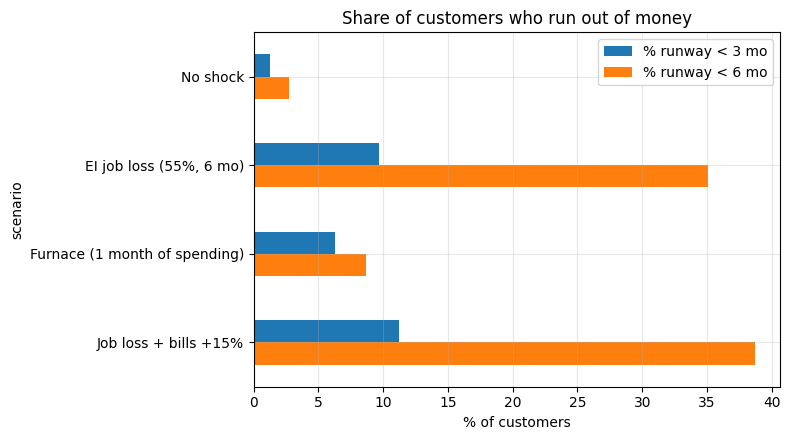

In [43]:
ax = frag.set_index("scenario")[["% runway < 3 mo", "% runway < 6 mo"]].plot.barh()
ax.set_xlabel("% of customers"); ax.set_title("Share of customers who run out of money"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [44]:
# WHO is hurt under EI job loss? Driver analysis.
profiles["income_band"] = pd.qcut(profiles.I.rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
profiles["spend_ratio"] = (profiles.S / profiles.I).replace([np.inf, -np.inf], np.nan)
profiles["spend_band"]  = pd.cut(profiles.spend_ratio, [0, .55, .8, 1.0, 1.2, np.inf],
                                 labels=["<55% of income", "55-80%", "80-100%", "100-120%", ">120%"])

def hurt(by):
    return (profiles.groupby(by, observed=True)
            .agg(n=("I", "size"), pct_ei_lt6=("rw_ei", lambda s: (s < 6).mean() * 100),
                 median_buffer=("B", "median"), median_spend=("S", "median"))
            .round(1))

display(hurt("income_band")); display(hurt("spend_band")); display(hurt("has_loan"))

,n,pct_ei_lt6,median_buffer,median_spend
income_band,,,,
Q1 low,1125,4.4,13850.5,1695.0
Q2,1125,20.7,17869.9,3773.5
Q3,1125,48.3,26957.7,10194.2
Q4 high,1125,66.9,34775.2,16425.6


,n,pct_ei_lt6,median_buffer,median_spend
spend_band,,,,
<55% of income,157,0.0,20135.2,1512.5
55-80%,1127,1.9,16184.0,2237.4
80-100%,1958,34.6,28485.0,10108.3
100-120%,892,81.1,20867.3,12089.2
>120%,285,54.4,19677.4,5506.1


,n,pct_ei_lt6,median_buffer,median_spend
has_loan,,,,
False,3818,29.5,21004.6,5751.9
True,682,66.1,28866.9,13726.2


In [45]:
# Finding B: does runway predict loan default?
# Label = `defaulted` (status B or D) over the 682 loans.

# **Leakage warning:** if features are computed over the *whole* history, they include months after the loan went bad. So built features two ways:
# 1. all months (easy, optimistic), and
# 2. only months before the loan started (honest: could the bank have seen this coming?).

In [46]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance

FEATS = ["I", "S", "B", "runway_base", "buffer_months", "spend_ratio", "income_cv", "spend_cv",
         "pct_months_below_zero", "avg_days_below_zero", "amount", "duration_months", "pay_to_income"]

def loan_dataset(ms, loans, pre_loan_only=False, min_months=3):
    if pre_loan_only:
        start = loans.set_index("account_id")["loan_start"].dt.to_period("M").astype(str)
        m = ms.copy()
        m["ls"] = m["account_id"].map(start)
        m = m[m["ls"].notna() & (m["month"] < m["ls"])].drop(columns="ls")
        n = m.groupby("account_id").size()
        m = m[m.account_id.isin(n[n >= min_months].index)]
    else:
        m = ms[ms.account_id.isin(loans.account_id)]
    prof = build_profiles(m, loans)
    prof = prof[prof.has_loan].join(
        loans.set_index("account_id")[["amount", "duration_months", "monthly_payment"]])
    prof["buffer_months"] = prof.B / prof.S.replace(0, np.nan)
    prof["spend_ratio"]   = prof.S / prof.I.replace(0, np.nan)
    prof["pay_to_income"] = prof.monthly_payment / prof.I.replace(0, np.nan)
    prof = prof.replace([np.inf, -np.inf], np.nan)
    return prof

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
models = {
    "Logistic regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Gradient boosting":   make_pipeline(SimpleImputer(strategy="median"),
                                         HistGradientBoostingClassifier(max_depth=3, learning_rate=.05,
                                                                        max_iter=150, random_state=0)),
}

results, datasets = [], {}
for label, pre in [("all months (leaky)", False), ("pre-loan months only (honest)", True)]:
    d = loan_dataset(ms, loans, pre_loan_only=pre)
    datasets[label] = d
    X, y = d[FEATS], d["defaulted"].astype(int)
    print(f"{label}: n={len(d)}, default rate={y.mean():.1%}")
    for name, mdl in models.items():
        auc = cross_val_score(mdl, X, y, cv=cv, scoring="roc_auc")
        results.append({"features": label, "model": name, "AUC mean": auc.mean(), "AUC std": auc.std()})
    # single-feature baseline: lower runway -> higher risk
    from sklearn.metrics import roc_auc_score
    results.append({"features": label, "model": "runway_base alone",
                    "AUC mean": roc_auc_score(y, -X["runway_base"].fillna(X["runway_base"].median())), "AUC std": np.nan})
pd.DataFrame(results).round(3)

all months (leaky): n=682, default rate=11.1%
pre-loan months only (honest): n=682, default rate=11.1%


,features,model,AUC mean,AUC std
0,all months (leaky),Logistic regression,0.986,0.023
1,all months (leaky),Gradient boosting,1.000,0.000
2,all months (leaky),runway_base alone,0.658,NaN
3,pre-loan months only (honest),Logistic regression,0.867,0.051
4,pre-loan months only (honest),Gradient boosting,0.836,0.044
5,pre-loan months only (honest),runway_base alone,0.548,NaN


In [47]:
# Default rate by runway band (all-months version)
d = datasets["all months (leaky)"]
d = d.assign(runway_band=pd.cut(d.runway_base, [-0.1, 3, 6, 12, 119.9, 120],
                                labels=["<3 mo", "3-6", "6-12", "12-120", "no shortfall"]))
print(d.groupby("runway_band", observed=True)["defaulted"].agg(n="size", default_rate="mean").round(3))

                n  default_rate
runway_band                    
<3 mo          15         0.800
3-6            13         0.538
6-12           48         0.208
12-120        133         0.068
no shortfall  473         0.080


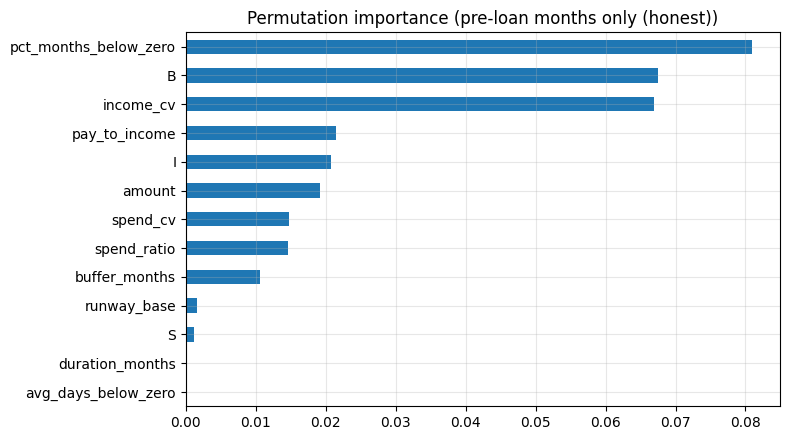

In [48]:
# What drives it? (permutation importance on gradient boosting, honest dataset if big enough)
label = "pre-loan months only (honest)" if len(datasets["pre-loan months only (honest)"]) > 150 else "all months (leaky)"
d = datasets[label]
X, y = d[FEATS], d["defaulted"].astype(int)
gb = models["Gradient boosting"].fit(X, y)
pi = permutation_importance(gb, X, y, n_repeats=20, random_state=0, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
imp.plot.barh(title=f"Permutation importance ({label})"); plt.tight_layout(); plt.show()

In [49]:
# Finding C: hidden fragility
#The official runway uses medians, so a customer with wildly swinging income can look safe. Here we bootstrap each customer's own monthly history: draw 6 random months of (income, spending), apply the shock, and ask how often the balance goes below zero.

In [50]:
def mc_fail_prob(ms, profiles, shock, months=6, n_sims=500, seed=0):
    rng = np.random.default_rng(seed)
    out = {}
    for acc, g in ms.groupby("account_id"):
        p = profiles.loc[acc]
        inc, sp = g.money_in.to_numpy(), g.money_out.to_numpy()
        idx = rng.integers(0, len(g), size=(n_sims, months))
        inc_after = shock.income_mult * inc[idx]
        sp_after  = sp[idx] + shock.bills_pct * p.H + shock.spend_add - (p.P if shock.loan_relief else 0)
        start = p.B - shock.one_off - shock.one_off_spend_mult * p.S
        path = start + np.cumsum(inc_after - sp_after, axis=1)
        out[acc] = (path.min(axis=1) < 0).mean() if start > 0 else 1.0
    return pd.Series(out, name="mc_fail_prob")

ei = PRESETS["EI job loss (55%, 6 mo)"]
profiles["mc_fail_ei"] = mc_fail_prob(ms, profiles, ei, months=6)
profiles["det_survives_ei"] = profiles.rw_ei >= 6          # official-formula answer

hidden = profiles[profiles.det_survives_ei & (profiles.mc_fail_ei >= 0.25)]
print(f"Official runway says they survive 6 months of EI, but >=25% of resampled futures fail: "
      f"{len(hidden)} accounts ({len(hidden)/len(profiles):.1%} of all, "
      f"{len(hidden)/profiles.det_survives_ei.sum():.1%} of 'safe' ones)")
print("\nVolatility of these 'hidden fragile' vs other 'safe' customers:")
safe = profiles[profiles.det_survives_ei]
print(pd.DataFrame({"hidden fragile": hidden[["income_cv", "spend_cv", "pct_months_below_zero"]].median(),
                    "other safe":     safe.drop(hidden.index)[["income_cv", "spend_cv", "pct_months_below_zero"]].median()}).round(3))

Official runway says they survive 6 months of EI, but >=25% of resampled futures fail: 844 accounts (18.8% of all, 28.9% of 'safe' ones)

Volatility of these 'hidden fragile' vs other 'safe' customers:
                       hidden fragile  other safe
income_cv                       0.285       0.214
spend_cv                        0.697       0.674
pct_months_below_zero           0.000       0.000


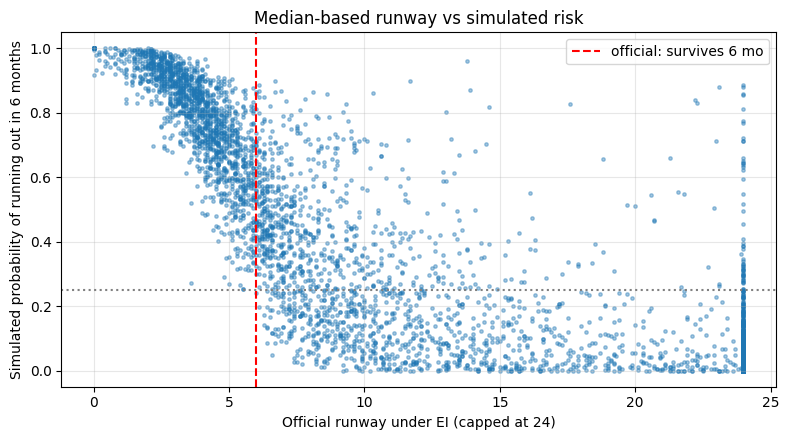

In [51]:
plt.scatter(profiles.rw_ei.clip(upper=24), profiles.mc_fail_ei, s=6, alpha=.4)
plt.axvline(6, color="r", ls="--", label="official: survives 6 mo"); plt.axhline(.25, color="gray", ls=":")
plt.xlabel("Official runway under EI (capped at 24)"); plt.ylabel("Simulated probability of running out in 6 months")
plt.legend(); plt.title("Median-based runway vs simulated risk"); plt.tight_layout(); plt.show()

In [52]:
# Customer personas (Kmeans)

In [53]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

seg = profiles[profiles.I > 0].copy()
Xs = pd.DataFrame({
    "log_income":  np.log1p(seg.I),
    "spend_ratio": seg.spend_ratio.clip(0, 3),
    "log_buffer":  np.log1p(seg.B.clip(lower=0)),
    "income_cv":   seg.income_cv.clip(upper=3),
    "pct_neg":     seg.pct_months_below_zero,
}).fillna(0)
Z = StandardScaler().fit_transform(Xs)

for k in range(3, 8):
    km = KMeans(k, n_init=10, random_state=0).fit(Z)
    print(k, "silhouette:", round(silhouette_score(Z, km.labels_), 3))

3 silhouette: 0.615
4 silhouette: 0.364
5 silhouette: 0.369
6 silhouette: 0.386
7 silhouette: 0.419


In [54]:
K = 3  # picked from the silhouette scores above
seg["persona"] = KMeans(K, n_init=10, random_state=0).fit_predict(Z)
persona_tbl = (seg.groupby("persona")
               .agg(n=("I", "size"), income=("I", "median"), spend=("S", "median"), buffer=("B", "median"),
                    spend_ratio=("spend_ratio", "median"), income_cv=("income_cv", "median"),
                    pct_ei_lt6=("rw_ei", lambda s: (s < 6).mean() * 100),
                    default_rate=("defaulted", "mean"))
               .round(2))
persona_tbl

,n,income,spend,buffer,spend_ratio,income_cv,pct_ei_lt6,default_rate
persona,,,,,,,,
0,304,1287.16,2321.76,18834.18,1.57,1.57,31.25,0.41
1,4133,8350.28,7862.48,22945.07,0.91,0.24,34.72,0.08
2,49,5444.91,7217.75,119.63,1.11,0.92,95.92,1.00


In [55]:
# Geography

In [56]:
geo = (profiles.join(accounts.set_index("account_id")[["district_id"]])
               .merge(districts, on="district_id", how="left"))
geo["buffer_months"] = geo.B / geo.S.replace(0, np.nan)

cols = ["unemployment_rate_2023", "average_salary", "urban_ratio_pct", "entrepreneurs_per_1000"]
targets = ["runway_base", "rw_ei", "buffer_months"]
print(geo[cols + targets].corr(method="spearman").loc[cols, targets].round(3))

print("\n% with <6 months runway under EI, by region:")
print(geo.groupby("region")["rw_ei"].agg(n="size", pct_lt6=lambda s: (s < 6).mean() * 100).round(1).sort_values("pct_lt6"))

                        runway_base  rw_ei  buffer_months
unemployment_rate_2023        0.005  0.007          0.012
average_salary               -0.017 -0.009         -0.005
urban_ratio_pct              -0.004  0.019          0.025
entrepreneurs_per_1000       -0.024 -0.024         -0.026

% with <6 months runway under EI, by region:
                   n  pct_lt6
region                       
west Bohemia     430     30.0
east Bohemia     544     33.3
south Moravia    778     33.5
north Bohemia    457     34.6
north Moravia    793     34.9
central Bohemia  574     35.2
Prague           554     39.7
south Bohemia    370     40.5


- Population Vulnerability: 35% of the 4,500 customers cannot survive 6 months on Employment Insurance (55% income). Furthermore, a surprise repair costing one month of spending leaves over 6% of customers with less than 3 months of runway.   

- Hidden Fragility (Standout Finding): Standard median-based runway formulas mask actual risk. By running Monte Carlo simulations on historical volatility, the code reveals that 844 customers (18.8% of the total base) who look mathematically "safe" actually run out of money in 25% or more of simulated futures.   

- Loan Defaults & Runway: Basic runway is a poor predictor of loan defaults (AUC 0.548). However, applying a Gradient Boosting model to pre-loan behavior (an honest, non-leaky dataset) yields a strong predictive AUC of 0.836.   

- Customer Personas: K-Means clustering identified three distinct customer profiles: a stable majority (4,133 accounts, 8% default rate), a low-income/high-spend group (304 accounts, 41% default rate), and a highly fragile segment with virtually no buffer (49 accounts, 100% default rate).  

- Geographic Independence: Resilience is driven by individual household habits, not local economies. District-level statistics like unemployment rates and average salaries showed virtually zero correlation (Spearman ~0.01) with customer runway.

In [57]:
# save outputs for the streamlit app

In [58]:
os.makedirs("outputs", exist_ok=True)
save_cols = [c for c in profiles.columns if c not in ("income_band", "spend_band")]
profiles[save_cols].to_csv("outputs/profiles.csv")            # app can read this instead of recomputing
frag.to_csv("outputs/fragility_table.csv", index=False)
seg[["persona"]].to_csv("outputs/personas.csv")
print("Saved:", os.listdir("outputs"))

Saved: ['personas.csv', 'fragility_table.csv', 'profiles.csv']


In [59]:
# Draft the headline sentence from real numbers (edit the wording to match your actual finding)
n = len(profiles)
ei6  = (profiles.rw_ei < 6).mean() * 100
fur3 = (profiles.rw_furnace < 3).mean() * 100
print(f"HEADLINE DRAFT: {ei6:.0f}% of {n:,} customers cannot cover 6 months of EI at 55% income; "
      f"a one-month-of-spending repair leaves {fur3:.0f}% with under 3 months of runway.")
print(f"Hidden risk: {len(hidden)} customers look safe on medians but fail in >=25% of simulated futures.")

HEADLINE DRAFT: 35% of 4,500 customers cannot cover 6 months of EI at 55% income; a one-month-of-spending repair leaves 6% with under 3 months of runway.
Hidden risk: 844 customers look safe on medians but fail in >=25% of simulated futures.


In [65]:
%%writefile app.py
import streamlit as st
import pandas as pd
import engine
import os

st.set_page_config(page_title="Banking4all", layout="wide", page_icon="🍊")

# --- DATA LOADING ---
@st.cache_data
def load_data():
    profiles = pd.read_csv("outputs/profiles.csv", index_col="account_id")
    fragility = pd.read_csv("outputs/fragility_table.csv")
    return profiles, fragility

profiles, fragility = load_data()

# --- HEADER & POPULATION FINDINGS ---
st.title("🍊 Tangerine: Banking4all")
st.markdown("### Financial Resilience Engine")

with st.expander("📊 View Population-Level Findings (Discovery)"):
    st.markdown("**Headline Insight:** 35% of customers cannot cover 6 months on EI at 55% income, and over 18% of 'safe-looking' customers hold hidden volatility risks.")
    st.dataframe(fragility, use_container_width=True)

# --- SIDEBAR: JUDGE CONTROLS ---
st.sidebar.header("🎯 Live Twist Controls")
account_id = st.sidebar.selectbox("1. Pick a Customer (account_id)", profiles.index)

st.sidebar.markdown("---")
st.sidebar.subheader("2. Apply a Shock")
shock_type = st.sidebar.selectbox("Select Scenario", ["No Shock"] + list(engine.PRESETS.keys()) + ["Custom Twist"])

if shock_type == "Custom Twist":
    inc_mult = st.sidebar.slider("Income Retained", 0.0, 1.0, 0.55, help="0.55 = EI standard")
    bills_pct = st.sidebar.slider("Bills Increase", 0.0, 1.0, 0.15, help="0.15 = 15% jump in rent/utilities")
    one_off = st.sidebar.number_input("Surprise One-off Cost ($)", min_value=0, value=1500, step=100)
    months = st.sidebar.slider("Shock Duration (Months)", min_value=1, max_value=24, value=6)
    active_shock = engine.Shock(income_mult=inc_mult, bills_pct=bills_pct, one_off=one_off, months=months, name="Custom Twist")
elif shock_type != "No Shock":
    active_shock = engine.PRESETS[shock_type]
else:
    active_shock = None

st.sidebar.markdown("---")
horizon = st.sidebar.slider("3. Chart Timeline (Months)", min_value=3, max_value=36, value=12)

# --- PART 1: KNOW THE CUSTOMER ---
st.markdown("---")
st.subheader(f"👤 Customer Profile: `{account_id}`")
p = engine.get_profile(profiles, account_id)

col1, col2, col3, col4 = st.columns(4)
col1.metric("Typical Income (I)", f"${p['I']:,.2f}")
col2.metric("Typical Spending (S)", f"${p['S']:,.2f}")
col3.metric("Available Buffer (B)", f"${p['B']:,.2f}")
col4.metric("Base Runway", engine.runway_label(p['runway_base']))

# --- PART 2: TAKE A SHOCK & INTERACTIVE CHART ---
if active_shock:
    st.markdown("---")
    st.subheader(f"⚡ Shock Applied: {active_shock.name}")

    r = engine.apply_shock(p, active_shock)

    scol1, scol2, scol3, scol4 = st.columns(4)
    scol1.metric("Income Under Shock", f"${r['income_after']:,.2f}", delta=f"${r['income_after'] - p['I']:,.2f}")
    scol2.metric("Spending Under Shock", f"${r['spending_after']:,.2f}", delta=f"${r['spending_after'] - p['S']:,.2f}", delta_color="inverse")
    scol3.metric("Post-Shock Gap", f"${r['gap']:,.2f}", help="Positive means spending exceeds income")
    scol4.metric("New Runway", engine.runway_label(r['runway_shock']))

    if not r['survives_shock_period']:
        st.error(f"⚠️ **Warning:** Customer runs out of money in month {r['runout_month']}.")
    else:
        st.success("✅ Customer survives the shock period without running out of cash.")

    # --- VISUALIZATION ---
    st.markdown("### 📉 Projected Balance Over Time")
    proj_df = engine.project_balance(p, active_shock, horizon=horizon)
    chart_df = proj_df.rename(columns={
        "balance": "Balance Under Shock",
        "baseline": "Normal Trajectory"
    }).set_index("month")[["Balance Under Shock", "Normal Trajectory"]]
    st.line_chart(chart_df, color=["#FF4B4B", "#29B09D"])

# --- PART 3: MAKE A PLAN ---
st.markdown("---")
st.subheader("🗓️ Action Plans")

pcol1, pcol2 = st.columns(2)

with pcol1:
    st.markdown("#### 🎯 Baseline Emergency Goal")
    goal = engine.goal_plan(p, target_months=3)
    st.write(f"**Target:** Build a 3-month emergency fund (${goal['target_fund']:,.2f})")

    if goal['already_there']:
        st.success(goal['note'])
    else:
        st.warning(f"**Gap to target:** ${goal['gap_to_target']:,.2f}")
        st.write(f"To reach this in 12 months, they need to save **${goal['required_monthly_saving']:,.2f}/month**.")
        st.info(goal['note'])
        if goal.get('trim_suggestions'):
            st.write("**Suggested trims from flexible spending:**")
            st.dataframe(pd.DataFrame(goal['trim_suggestions']), use_container_width=True)

with pcol2:
    st.markdown("#### 🛡️ Backup Plan (Under Shock)")
    if active_shock:
        backup = engine.backup_plan(p, active_shock)
        st.write(f"**Objective:** Survive {backup['duration_months']} months under current shock conditions.")

        if not backup['needs_action']:
            st.success(backup['summary'])
        else:
            st.warning(backup['summary'])
            st.write(f"**Required Monthly Cut:** ${backup['required_cut']:,.2f}")

            st.write("**Available Relief Options:**")
            st.dataframe(pd.DataFrame(backup['options']), use_container_width=True)

            if not backup['covered_by_cuts']:
                st.error(f"Even with all cuts, a bridge of **${backup['bridge_needed_total']:,.2f}** is still required.")
    else:
        st.info("Apply a shock from the sidebar to generate a backup plan.")

# --- PART 4: AI SUMMARY ---
st.markdown("---")
st.subheader("✨ AI Insights")

if st.button("Generate AI Summary of this Situation"):
    import google.generativeai as genai

    # Attempt to load GEMINI_API_KEY from Colab's user_secrets or environment variables
    api_key = os.environ.get("GEMINI_API_KEY")
    if not api_key:
        try:
            from google.colab import userdata
            api_key = userdata.get("GEMINI_API_KEY")
        except Exception:
            pass

    if not api_key:
        try:
            api_key = st.secrets.get("GEMINI_API_KEY")
        except Exception:
            pass

    if not api_key:
        st.error("GEMINI_API_KEY not found in environment variables, Colab Secrets, or Streamlit secrets.")
    else:
        try:
            genai.configure(api_key=api_key)
            model = genai.GenerativeModel('gemini-2.5-flash')

            prompt = f"Write a concise, 2-3 sentence summary of the following financial situation for a bank advisor. "
            prompt += f"Typical Income: ${p['I']:,.2f}. Typical Spending: ${p['S']:,.2f}. Available Buffer: ${p['B']:,.2f}. "

            if active_shock:
                prompt += f"They have experienced a shock: {active_shock.name}. "
                prompt += f"Their new income is ${r['income_after']:,.2f} and spending is ${r['spending_after']:,.2f}. "
                prompt += f"Their new runway is {r['runway_label']}. "
                if not r['survives_shock_period']:
                    prompt += "They will run out of money. "
            else:
                prompt += "They are not currently experiencing an economic shock. "

            prompt += "Make it empathetic but professional."

            with st.spinner("Generating summary..."):
                response = model.generate_content(prompt)
                st.success(response.text)

        except Exception as e:
            st.error(f"Error generating summary: {e}")

Overwriting app.py


In [61]:
# # Install Streamlit if you haven't already
!pip install -q streamlit

# # Install localtunnel to expose the port
# !npm install localtunnel

# # Start the Streamlit server in the background and expose port 8501
# import urllib
# print("Password/Enpoint IP for localtunnel is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip("\n"))
# !streamlit run app.py &> /dev/null & npx localtunnel --port 8501

In [62]:
!pip install -q google-generativeai

# 1. Kill any running Streamlit instances
!pkill -f streamlit

# 2. Run Streamlit with Colab-friendly settings
!streamlit run app.py --server.enableCORS false --server.enableXsrfProtection false &>/dev/null &

# 3. Wait for the server to start
import time
time.sleep(3)

# 4. Open the proxy tab
from google.colab import output
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [63]:
# Gemini API key config
import os
from google.colab import userdata

try:
    # Récupère la clé depuis le gestionnaire de secrets de Colab
    api_key = userdata.get('GEMINI_API_KEY')
    os.environ['GEMINI_API_KEY'] = api_key
    print("GEMINI_API_KEY sucessfully loaded!")
except Exception as e:
    print("Impossible to load 'GEMINI_API_KEY'.")
    print("Add it to the google collab secrets.")

GEMINI_API_KEY sucessfully loaded!


In [66]:
# 1. Kill any running Streamlit instances
!pkill -f streamlit

# 2. Run Streamlit
!streamlit run app.py --server.enableCORS false --server.enableXsrfProtection false &>/dev/null &

# 3. Wait for startup
import time
time.sleep(3)

# 4. Open port in a new browser tab
from google.colab import output
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>